<a href="https://colab.research.google.com/github/rorellana-analytics/data-analytics-portfolio/blob/main/Analisis_Ventas_Globales_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ventas en Europa y Asia (2010–2017): ¿dónde concentrar el esfuerzo comercial?

**Autor:** Rafael Ernesto Orellana Giménez · Analista de Datos · [GitHub](https://github.com/rorellana-analytics) · [LinkedIn](https://www.linkedin.com/in/rafael-ernesto-orellana-gim%C3%A9nez-700346264)

**Pregunta de negocio:** ¿Qué categorías y países aportan más beneficio y dónde conviene concentrar esfuerzo?

> **Nota de origen y transparencia de datos:** `events.csv`, `products.csv` y `countries.csv` son un conjunto de datos ficticio, trabajado en el curso *Google Sheets* de la plataforma Kodree. No son registros de una empresa real. Los importes elevados reflejan el ejercicio y no deben leerse como estados financieros.

**Alcance:** 12 categorías, 45 países de 2 regiones (Europa y Asia) y pedidos de enero de 2010 a julio de 2017. El nombre del archivo conserva «Globales» por exigencia de la evaluación; el análisis **no es global**.

### Decisiones de limpieza
- Se conserva el código ISO `'NA'` de Namibia (`keep_default_na=False`).
- Se auditan los caracteres no ASCII. No hay homógrafos que corregir.
- Se eliminan 2 pedidos sin `Units Sold` (no se imputan). Quedan 1,328 pedidos, igual que en la hoja de cálculo.
- 82 pedidos (6.2 %) no tienen país. Se etiquetan «Sin asignar»: entran en los totales y salen de los cortes geográficos (`df_geo`).
- Las cifras del informe se calculan en el código. Las conclusiones usan pruebas estadísticas (α = 0.05).

**Contenido:** 1. Carga · 2. Auditoría y limpieza · 3. KPIs · 4. Categorías y Pareto · 5. Geografía y canal · 6. Logística · 7. Tiempo · 8. Hallazgos · 9. Limitaciones

**Uso en Colab:** ejecuta todas las celdas. Si no existe la carpeta `Data/`, la celda de carga pide subir los 3 CSV.

In [39]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from IPython.display import display, Markdown

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (11, 5)
pd.options.display.float_format = "{:,.2f}".format

DATA_DIR = Path("Data")
FIG_DIR = Path("Images")
FIG_DIR.mkdir(exist_ok=True)
ALPHA = 0.05

def usd(v):
    return f"${v:,.0f}"

def guardar(nombre):
    plt.tight_layout()
    plt.savefig(FIG_DIR / nombre, dpi=130)
    plt.show()

## 1. Carga de datos

In [40]:
ARCHIVOS = ("events.csv", "products.csv", "countries.csv")

if not all((DATA_DIR / f).exists() for f in ARCHIVOS):
    try:
        from google.colab import files  # solo existe en Colab
        DATA_DIR.mkdir(exist_ok=True)
        print("Sube events.csv, products.csv y countries.csv")
        for nombre, contenido in files.upload().items():
            (DATA_DIR / nombre).write_bytes(contenido)
    except ImportError:
        pass

faltan = [f for f in ARCHIVOS if not (DATA_DIR / f).exists()]
if faltan:
    raise FileNotFoundError(f"Faltan en {DATA_DIR}/: {faltan}")

events = pd.read_csv(DATA_DIR / "events.csv")
products = pd.read_csv(DATA_DIR / "products.csv")
# keep_default_na=False: evita que el código ISO 'NA' (Namibia) se lea como nulo
countries = pd.read_csv(DATA_DIR / "countries.csv", keep_default_na=False).replace({"": np.nan})

for nombre, t in [("events", events), ("products", products), ("countries", countries)]:
    print(f"{nombre}: {t.shape[0]:,} filas x {t.shape[1]} columnas")
display(events.head(3))

events: 1,330 filas x 10 columnas
products: 12 filas x 2 columnas
countries: 249 filas x 5 columnas


,Order ID,Order Date,Ship Date,Order Priority,Country Code,Product ID,Sales Channel,Units Sold,Unit Price,Unit Cost
0,100640618,10/8/2014,10/18/2014,M,NOR,2103,Online,650.00,205.70,117.11
1,100983083,8/11/2016,8/11/2016,C,SRB,2103,Offline,"1,993.00",205.70,117.11
2,101025998,7/18/2014,8/11/2014,M,NaN,7940,Online,"4,693.00",668.27,502.54


## 2. Auditoría y limpieza

In [41]:
def resumen_nulos(t):
    n = t.isna().sum()
    return pd.DataFrame({"nulos": n, "%": (n / len(t) * 100).round(2)})[n > 0]

for nombre, t in [("events", events), ("products", products), ("countries", countries)]:
    print(f"--- Nulos en {nombre} ---")
    r = resumen_nulos(t)
    print(r if len(r) else "Sin nulos")

print("\nDuplicados exactos en events:", events.duplicated().sum())
print("Order ID repetidos:", events["Order ID"].duplicated().sum())
print("\nSales Channel (valores crudos):")
print(events["Sales Channel"].value_counts(dropna=False))
print("\nOrder Priority (valores crudos):")
print(events["Order Priority"].value_counts(dropna=False))

no_ascii = {c: int(events[c].dropna().astype(str).str.contains(r"[^\x00-\x7F]").sum())
            for c in events.select_dtypes("object").columns}
print("\nCaracteres no ASCII en events:", no_ascii)
print("Namibia en countries:", countries.loc[countries["name"] == "Namibia", ["alpha-2", "alpha-3"]].values.tolist())
print("Líneas de producto por Order ID (máx.):", events.groupby("Order ID").size().max())

--- Nulos en events ---
              nulos    %
Country Code     82 6.17
Units Sold        2 0.15
--- Nulos en products ---
Sin nulos
--- Nulos en countries ---
            nulos    %
region          1 0.40
sub-region      1 0.40

Duplicados exactos en events: 0
Order ID repetidos: 0

Sales Channel (valores crudos):
Sales Channel
Offline    667
Online     660
online       3
Name: count, dtype: int64

Order Priority (valores crudos):
Order Priority
M     353
H     335
L     334
C     305
 C      2
M       1
Name: count, dtype: int64

Caracteres no ASCII en events: {'Order Date': 0, 'Ship Date': 0, 'Order Priority': 0, 'Country Code': 0, 'Sales Channel': 0}
Namibia en countries: [['NA', 'NAM']]
Líneas de producto por Order ID (máx.): 1


In [42]:
ev = events.copy()
for c in ["Sales Channel", "Order Priority", "Country Code"]:
    ev[c] = ev[c].str.strip()
ev["Sales Channel"] = ev["Sales Channel"].str.capitalize()
ev["Order Priority"] = ev["Order Priority"].str.upper()
ev["Country Code"] = ev["Country Code"].str.upper()
ev["Order Date"] = pd.to_datetime(ev["Order Date"], format="%m/%d/%Y")
ev["Ship Date"] = pd.to_datetime(ev["Ship Date"], format="%m/%d/%Y")

# Se eliminan (no se imputan) los pedidos sin Units Sold: no se inventan ventas.
n_sin_unidades = int(ev["Units Sold"].isna().sum())
ev = ev.dropna(subset=["Units Sold"]).copy()
ev["Units Sold"] = ev["Units Sold"].astype(int)

ev["revenue"] = ev["Units Sold"] * ev["Unit Price"]
ev["cost"] = ev["Units Sold"] * ev["Unit Cost"]
ev["profit"] = ev["revenue"] - ev["cost"]
ev["shipping_days"] = (ev["Ship Date"] - ev["Order Date"]).dt.days
ev["year"] = ev["Order Date"].dt.year
ev["month"] = ev["Order Date"].dt.month
ev["weekday"] = ev["Order Date"].dt.day_name()

assert (ev["shipping_days"] >= 0).all(), "Envíos anteriores al pedido"
assert (ev["Unit Cost"] <= ev["Unit Price"]).all(), "Costo mayor que precio"
assert ev["Order ID"].is_unique

df = (ev.merge(products.rename(columns={"id": "Product ID", "item_type": "category"}),
               on="Product ID", how="left", validate="m:1")
        .merge(countries.rename(columns={"name": "country", "alpha-3": "Country Code", "sub-region": "sub_region"})
                        [["Country Code", "country", "region", "sub_region"]],
               on="Country Code", how="left", validate="m:1"))
assert df["category"].notna().all(), "Productos sin categoría"

sin_pais = df["country"].isna()
n_sin_pais = int(sin_pais.sum())
df["country"] = df["country"].fillna("Sin asignar")
df["region"] = df["region"].fillna("Sin asignar")
df_geo = df[~sin_pais].copy()

print(f"Pedidos eliminados por Units Sold nulo: {n_sin_unidades}")
print(f"Pedidos finales: {len(df):,} | sin país (solo excluidos de cortes geográficos): {n_sin_pais} ({n_sin_pais/len(df):.1%})")
print(f"Con país: {len(df_geo):,} | países: {df_geo['country'].nunique()} | regiones: {sorted(df_geo['region'].unique())}")

Pedidos eliminados por Units Sold nulo: 2
Pedidos finales: 1,328 | sin país (solo excluidos de cortes geográficos): 82 (6.2%)
Con país: 1,246 | países: 45 | regiones: ['Asia', 'Europe']


## 3. KPIs globales

In [43]:
K = {"pedidos": len(df), "unidades": int(df["Units Sold"].sum()), "ingresos": df["revenue"].sum(),
     "costos": df["cost"].sum(), "beneficio": df["profit"].sum()}
K["margen"] = K["beneficio"] / K["ingresos"]
K["ticket"] = K["ingresos"] / K["pedidos"]
display(pd.DataFrame({"Indicador": ["Pedidos", "Unidades", "Ingresos", "Costos", "Beneficio", "Margen bruto", "Ticket promedio", "Países", "Días de envío (media)"],
                      "Valor": [f"{K['pedidos']:,}", f"{K['unidades']:,}", usd(K["ingresos"]), usd(K["costos"]), usd(K["beneficio"]),
                                f"{K['margen']:.2%}", usd(K["ticket"]), df_geo["country"].nunique(), f"{df['shipping_days'].mean():.2f}"]}).set_index("Indicador"))

,Valor
Indicador,
Pedidos,"1,328"
Unidades,"6,576,524"
Ingresos,"$1,702,129,408"
Costos,"$1,200,694,949"
Beneficio,"$501,434,459"
Margen bruto,29.46%
Ticket promedio,"$1,281,724"
Países,45
Días de envío (media),24.79


## 4. Categorías y Pareto

,pedidos,unidades,ingresos,costos,beneficio,precio_unit,costo_unit,margen,margen_unit,%_beneficio,%_acum
category,,,,,,,,,,,
Cosmetics,114,"533,291","233,154,825","140,431,519","92,723,306",437.200000,263.330000,39.8%,173.870000,18.5%,18.5%
Office Supplies,123,"617,641","402,213,996","324,236,819","77,977,176",651.210000,524.960000,19.4%,126.250000,15.6%,34.0%
Household,97,"440,249","294,205,199","221,242,732","72,962,467",668.270000,502.540000,24.8%,165.730000,14.6%,48.6%
Baby Food,112,"562,706","143,647,588","89,706,591","53,940,997",255.280000,159.420000,37.6%,95.860000,10.8%,59.4%
Clothes,105,"591,385","64,626,553","21,195,238","43,431,314",109.280000,35.840000,67.2%,73.440000,8.7%,68.0%
Cereal,103,"465,685","95,791,404","54,536,370","41,255,034",205.700000,117.110000,43.1%,88.590000,8.2%,76.2%
Vegetables,114,"582,544","89,746,729","52,970,726","36,776,003",154.060000,90.930000,41.0%,63.130000,7.3%,83.6%
Meat,110,"530,380","223,762,018","193,424,282","30,337,736",421.890000,364.690000,13.6%,57.200000,6.1%,89.6%
Snacks,103,"490,160","74,788,613","47,761,190","27,027,422",152.580000,97.440000,36.1%,55.140000,5.4%,95.0%


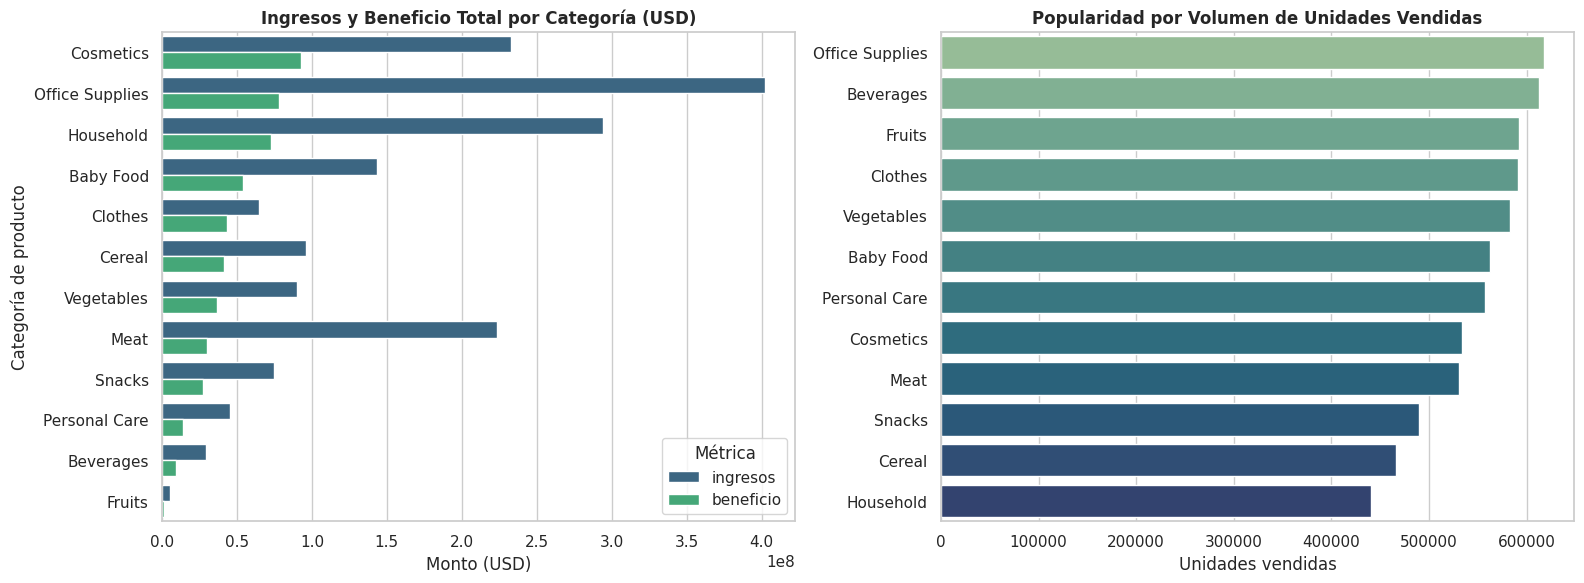

In [44]:
cat = (df.groupby("category")
         .agg(pedidos=("Order ID", "count"), unidades=("Units Sold", "sum"), ingresos=("revenue", "sum"),
              costos=("cost", "sum"), beneficio=("profit", "sum"),
              precio_unit=("Unit Price", "first"), costo_unit=("Unit Cost", "first"))
         .sort_values("beneficio", ascending=False))
assert df.groupby("category")["Unit Price"].nunique().max() == 1
cat["margen"] = cat["beneficio"] / cat["ingresos"]
cat["margen_unit"] = cat["precio_unit"] - cat["costo_unit"]
cat["%_beneficio"] = cat["beneficio"] / cat["beneficio"].sum()
cat["%_acum"] = cat["%_beneficio"].cumsum()
display(cat.style.format({"ingresos": "{:,.0f}", "costos": "{:,.0f}", "beneficio": "{:,.0f}", "margen": "{:.1%}",
                          "%_beneficio": "{:.1%}", "%_acum": "{:.1%}", "unidades": "{:,}"}))

cat_summary = cat.reset_index()
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
melt = cat_summary.melt(id_vars="category", value_vars=["ingresos", "beneficio"], var_name="Métrica", value_name="USD")
sns.barplot(data=melt, y="category", x="USD", hue="Métrica", order=cat_summary["category"], ax=axes[0], palette="viridis")
axes[0].set_title("Ingresos y Beneficio Total por Categoría (USD)", fontweight="bold")
axes[0].set_xlabel("Monto (USD)"); axes[0].set_ylabel("Categoría de producto")
cu = cat_summary.sort_values("unidades", ascending=False)
sns.barplot(data=cu, y="category", x="unidades", order=cu["category"], hue="category", palette="crest", legend=False, ax=axes[1])
axes[1].set_title("Popularidad por Volumen de Unidades Vendidas", fontweight="bold")
axes[1].set_xlabel("Unidades vendidas"); axes[1].set_ylabel("")
guardar("01_ingresos_beneficio_unidades.png")

Office Supplies factura más que cualquier otra categoría, pero su margen es bajo. Fruits y Beverages venden muchas unidades con poco beneficio: el cuello de botella es el precio unitario.

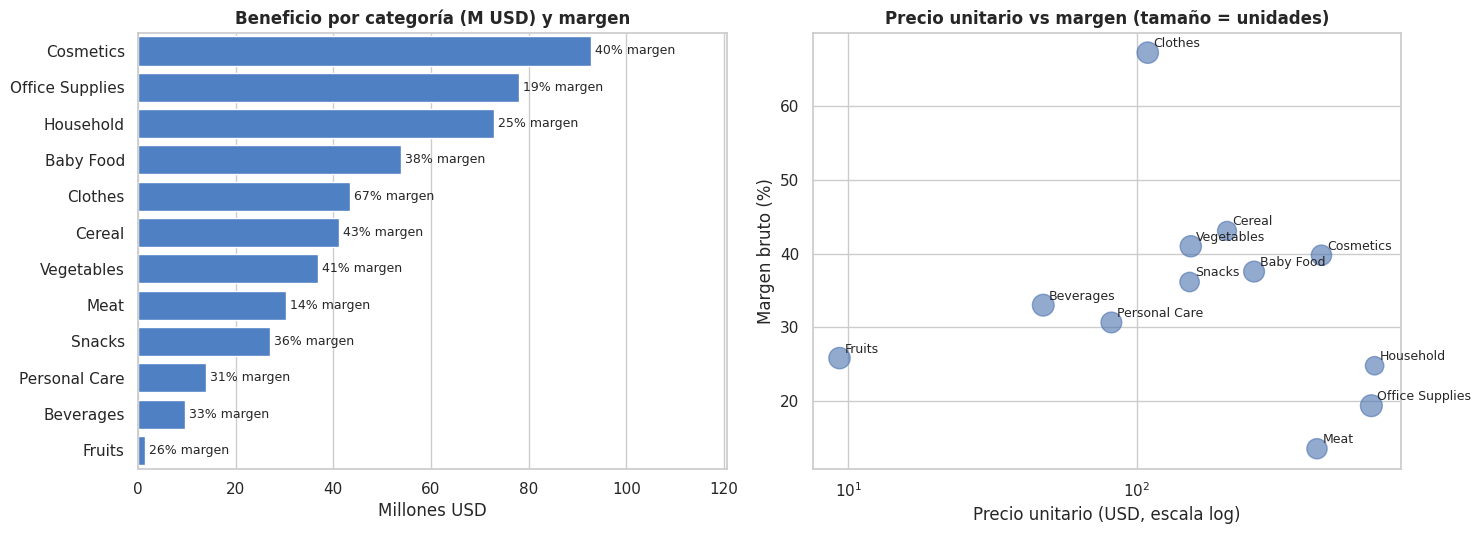

In [45]:
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5))
sns.barplot(x=cat["beneficio"] / 1e6, y=cat.index, color="#3b7dd8", ax=ax[0])
ax[0].set_title("Beneficio por categoría (M USD) y margen", fontweight="bold")
ax[0].set_xlabel("Millones USD"); ax[0].set_ylabel("")
for i, (b, m) in enumerate(zip(cat["beneficio"] / 1e6, cat["margen"])):
    ax[0].text(b, i, f" {m:.0%} margen", va="center", fontsize=9)
ax[0].set_xlim(0, cat["beneficio"].max() / 1e6 * 1.3)
ax[1].scatter(cat["precio_unit"], cat["margen"] * 100, s=cat["unidades"] / 2500, alpha=.6)
for n, r in cat.iterrows():
    ax[1].annotate(n, (r["precio_unit"], r["margen"] * 100), fontsize=9, xytext=(4, 4), textcoords="offset points")
ax[1].set_xscale("log")
ax[1].set_title("Precio unitario vs margen (tamaño = unidades)", fontweight="bold")
ax[1].set_xlabel("Precio unitario (USD, escala log)"); ax[1].set_ylabel("Margen bruto (%)")
guardar("02_beneficio_precio_margen.png")

,category,beneficio,margen,%_beneficio,%_acum,clase_ABC
0,Cosmetics,"92,723,306",39.8%,18.5%,18.5%,A
1,Office Supplies,"77,977,176",19.4%,15.6%,34.0%,A
2,Household,"72,962,467",24.8%,14.6%,48.6%,A
3,Baby Food,"53,940,997",37.6%,10.8%,59.4%,A
4,Clothes,"43,431,314",67.2%,8.7%,68.0%,A
5,Cereal,"41,255,034",43.1%,8.2%,76.2%,A
6,Vegetables,"36,776,003",41.0%,7.3%,83.6%,A
7,Meat,"30,337,736",13.6%,6.1%,89.6%,B
8,Snacks,"27,027,422",36.1%,5.4%,95.0%,B
9,Personal Care,"13,975,411",30.7%,2.8%,97.8%,C


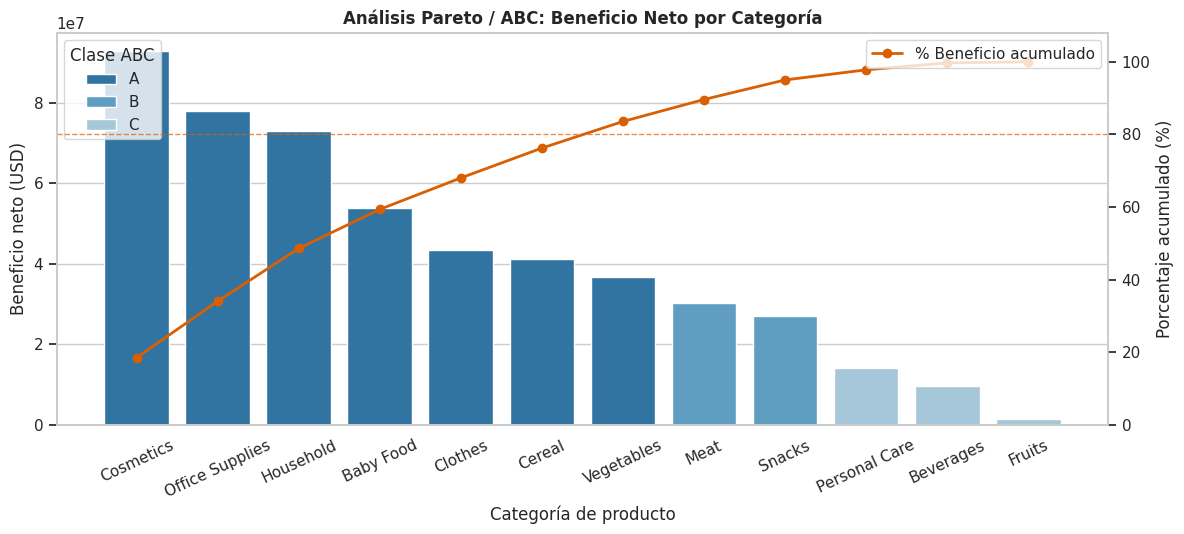

Hacen falta **7 de 12** categorías para llegar al 80 % del beneficio. Las 4 primeras suman 59.4%; las 3 últimas, 5.0%. La clase A agrupa 7 categorías, así que **no existe una concentración 80/20**: la clasificación ABC es solo orientativa.

In [46]:
pareto = cat[["beneficio", "margen", "%_beneficio", "%_acum"]].reset_index()
previo = pareto["%_acum"].shift(1).fillna(0) * 100
pareto["clase_ABC"] = np.where(previo <= 80, "A", np.where(previo <= 95, "B", "C"))
display(pareto.style.format({"beneficio": "{:,.0f}", "margen": "{:.1%}", "%_beneficio": "{:.1%}", "%_acum": "{:.1%}"}))

fig, ax1 = plt.subplots(figsize=(12, 5.5))
sns.barplot(data=pareto, x="category", y="beneficio", hue="clase_ABC", dodge=False,
            palette={"A": "#1f77b4", "B": "#4fa3d1", "C": "#9ecae1"}, ax=ax1)
ax1.set_title("Análisis Pareto / ABC: Beneficio Neto por Categoría", fontweight="bold")
ax1.set_xlabel("Categoría de producto"); ax1.set_ylabel("Beneficio neto (USD)")
ax1.tick_params(axis="x", rotation=25); ax1.legend(title="Clase ABC", loc="upper left")
ax2 = ax1.twinx()
ax2.plot(range(len(pareto)), pareto["%_acum"] * 100, color="#d95f02", marker="o", linewidth=2, label="% Beneficio acumulado")
ax2.axhline(80, color="#d95f02", linestyle="--", linewidth=1, alpha=0.7)
ax2.set_ylabel("Porcentaje acumulado (%)"); ax2.set_ylim(0, 108); ax2.legend(loc="upper right"); ax2.grid(False)
guardar("03_pareto_abc.png")

n_cat = len(cat)
n_80 = int((cat["%_acum"] < 0.80).sum() + 1)
top4 = cat["%_beneficio"].head(4).sum()
bottom3 = cat["%_beneficio"].tail(3).sum()
display(Markdown(f"Hacen falta **{n_80} de {n_cat}** categorías para llegar al 80 % del beneficio. Las 4 primeras suman {top4:.1%}; las 3 últimas, {bottom3:.1%}. "
                 f"La clase A agrupa {int((pareto['clase_ABC']=='A').sum())} categorías, así que **no existe una concentración 80/20**: la clasificación ABC es solo orientativa."))

## 5. Geografía y canal

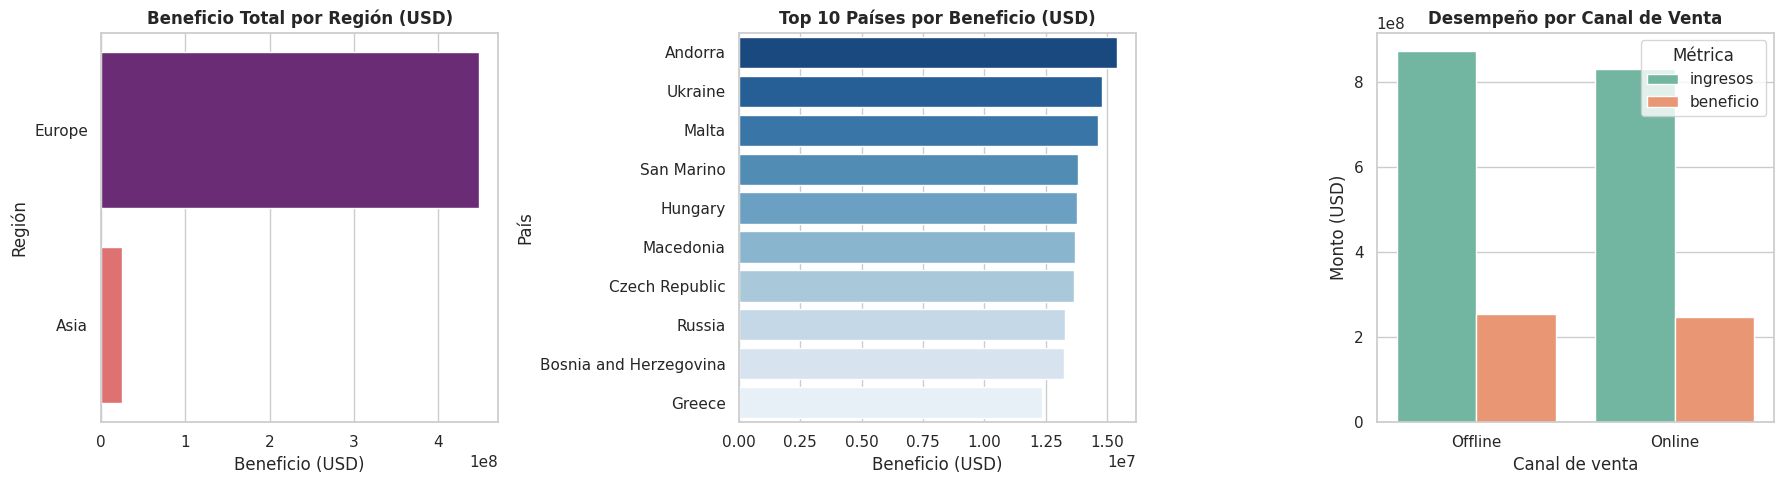

,pedidos,ingresos,beneficio,margen,beneficio_x_pedido
region,,,,,
Asia,82,"93,330,887.37","25,152,252.95",0.27,"306,734.79"
Europe,1164,"1,505,652,873.89","448,556,782.11",0.30,"385,358.06"
Sin asignar,82,"103,145,646.95","27,725,423.94",0.27,"338,114.93"


,pedidos,ingresos,beneficio,beneficio_medio,margen
Sales Channel,,,,,
Offline,665,"871,760,623.88","253,466,518.81","381,152.66",0.29
Online,663,"830,368,784.33","247,967,940.19","374,008.96",0.30


Mann-Whitney beneficio por pedido Online vs Offline: p = 0.664


In [47]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
reg_summary = df_geo.groupby("region", as_index=False)["profit"].sum().sort_values("profit", ascending=False)
sns.barplot(data=reg_summary, x="profit", y="region", order=reg_summary["region"], hue="region", palette="magma", legend=False, ax=axes[0])
axes[0].set_title("Beneficio Total por Región (USD)", fontweight="bold"); axes[0].set_xlabel("Beneficio (USD)"); axes[0].set_ylabel("Región")
top_countries = df_geo.groupby("country", as_index=False)["profit"].sum().sort_values("profit", ascending=False).head(10)
sns.barplot(data=top_countries, x="profit", y="country", order=top_countries["country"], hue="country", palette="Blues_r", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Países por Beneficio (USD)", fontweight="bold"); axes[1].set_xlabel("Beneficio (USD)"); axes[1].set_ylabel("País")
canal_summary = df.groupby("Sales Channel", as_index=False).agg(ingresos=("revenue", "sum"), beneficio=("profit", "sum")).sort_values("beneficio", ascending=False)
cm = canal_summary.melt(id_vars="Sales Channel", value_vars=["ingresos", "beneficio"], var_name="Métrica", value_name="USD")
sns.barplot(data=cm, x="Sales Channel", y="USD", hue="Métrica", order=canal_summary["Sales Channel"], palette="Set2", ax=axes[2])
axes[2].set_title("Desempeño por Canal de Venta", fontweight="bold"); axes[2].set_xlabel("Canal de venta"); axes[2].set_ylabel("Monto (USD)")
guardar("04_region_paises_canal.png")

reg = df.groupby("region").agg(pedidos=("Order ID", "count"), ingresos=("revenue", "sum"), beneficio=("profit", "sum"))
reg["margen"] = reg["beneficio"] / reg["ingresos"]
reg["beneficio_x_pedido"] = reg["beneficio"] / reg["pedidos"]
display(reg)
canal = df.groupby("Sales Channel").agg(pedidos=("Order ID", "count"), ingresos=("revenue", "sum"), beneficio=("profit", "sum"), beneficio_medio=("profit", "mean"))
canal["margen"] = canal["beneficio"] / canal["ingresos"]
display(canal)
_, p_canal = stats.mannwhitneyu(df.loc[df["Sales Channel"] == "Online", "profit"], df.loc[df["Sales Channel"] == "Offline", "profit"])
print(f"Mann-Whitney beneficio por pedido Online vs Offline: p = {p_canal:.3f}")

,country,total_pedidos,unidades_vendidas,ingresos_usd,beneficio_usd,dias_envio_prom
0,Andorra,40,185686,"47,756,693.17","15,410,036.63",26.27
1,San Marino,40,192228,"47,883,708.48","13,792,992.81",21.70
2,Romania,34,166882,"34,286,150.85","10,793,548.69",24.94
3,Bosnia and Herzegovina,33,153545,"50,117,508.49","13,257,602.77",26.06
4,Ukraine,33,164577,"53,252,317.54","14,804,925.74",25.76
5,Greece,32,176859,"38,699,541.70","12,324,450.13",23.00
6,Macedonia,32,203078,"49,222,085.25","13,684,099.95",23.22
7,Malta,32,173641,"47,145,320.81","14,610,127.88",21.56
8,Russia,32,165954,"46,051,659.81","13,267,682.64",27.38
9,Czech Republic,31,142446,"53,543,932.14","13,635,593.78",25.23


,country,total_pedidos,unidades_vendidas,ingresos_usd,beneficio_usd,dias_envio_prom
0,Andorra,40,185686,"47,756,693.17","15,410,036.63",26.27
1,Ukraine,33,164577,"53,252,317.54","14,804,925.74",25.76
2,Malta,32,173641,"47,145,320.81","14,610,127.88",21.56
3,San Marino,40,192228,"47,883,708.48","13,792,992.81",21.70
4,Hungary,25,152242,"42,408,249.12","13,786,231.03",32.64
5,Macedonia,32,203078,"49,222,085.25","13,684,099.95",23.22
6,Czech Republic,31,142446,"53,543,932.14","13,635,593.78",25.23
7,Russia,32,165954,"46,051,659.81","13,267,682.64",27.38
8,Bosnia and Herzegovina,33,153545,"50,117,508.49","13,257,602.77",26.06
9,Greece,32,176859,"38,699,541.70","12,324,450.13",23.00


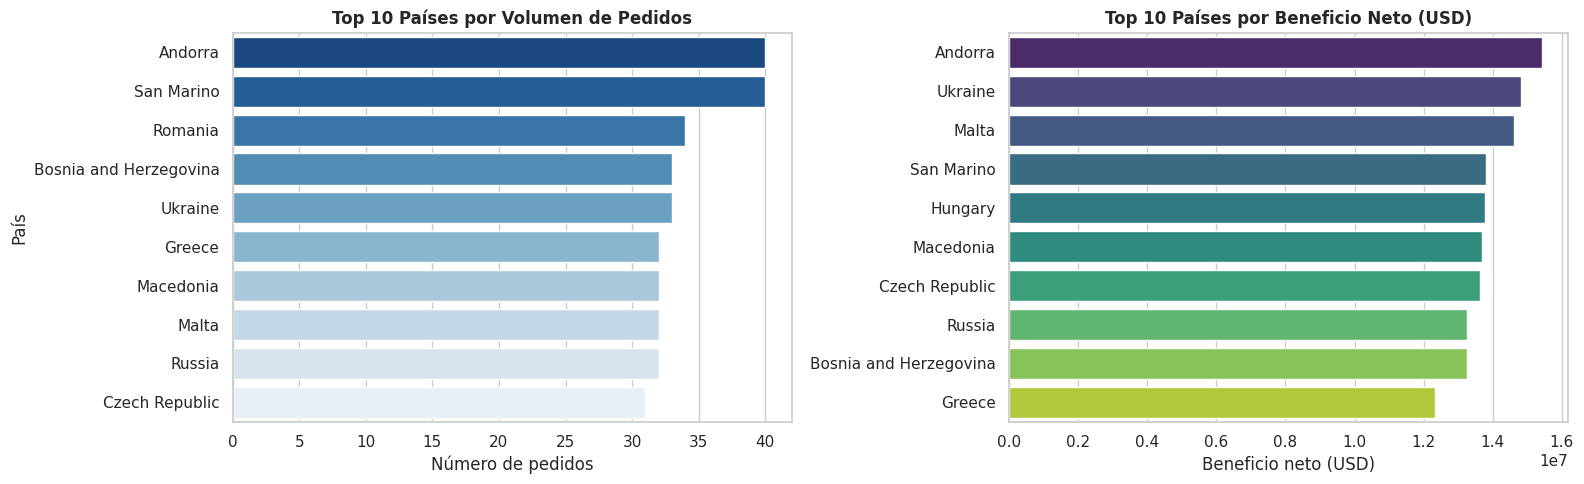

In [48]:
resumen_paises = (df_geo.groupby("country", as_index=False)
                  .agg(total_pedidos=("Order ID", "nunique"), unidades_vendidas=("Units Sold", "sum"),
                       ingresos_usd=("revenue", "sum"), beneficio_usd=("profit", "sum"), dias_envio_prom=("shipping_days", "mean")))
top10_pedidos = resumen_paises.sort_values("total_pedidos", ascending=False).head(10).reset_index(drop=True)
top10_beneficio = resumen_paises.sort_values("beneficio_usd", ascending=False).head(10).reset_index(drop=True)
display(top10_pedidos); display(top10_beneficio)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(data=top10_pedidos, x="total_pedidos", y="country", order=top10_pedidos["country"], hue="country", palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("Top 10 Países por Volumen de Pedidos", fontweight="bold"); axes[0].set_xlabel("Número de pedidos"); axes[0].set_ylabel("País")
sns.barplot(data=top10_beneficio, x="beneficio_usd", y="country", order=top10_beneficio["country"], hue="country", palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Top 10 Países por Beneficio Neto (USD)", fontweight="bold"); axes[1].set_xlabel("Beneficio neto (USD)"); axes[1].set_ylabel("")
guardar("05_top10_pedidos_beneficio.png")

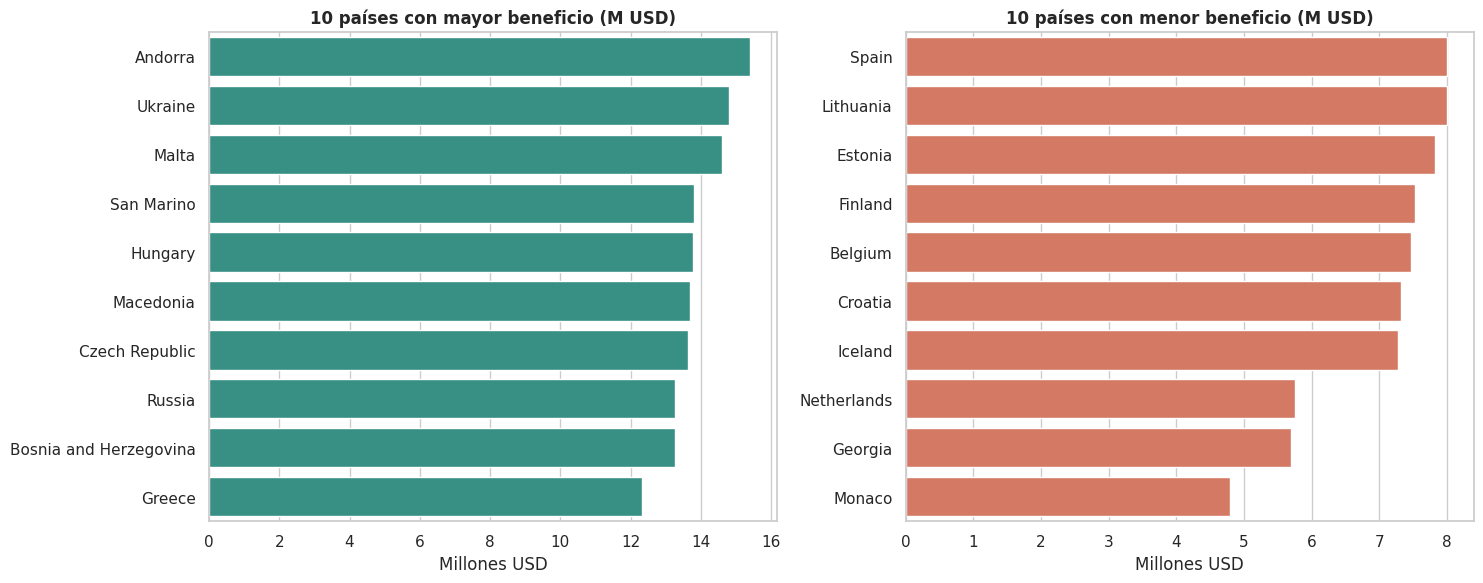

Top 10 = 29.3% del beneficio con país (reparto parejo en 45 países: 22.2%). Mayor/menor: 3.2x
Kruskal-Wallis beneficio por pedido entre países: H = 27.7, p = 0.974
Chi-cuadrado país x categoría: p = 0.727


In [49]:
pais = resumen_paises.set_index("country").sort_values("beneficio_usd", ascending=False)
pais["%_acum"] = pais["beneficio_usd"].cumsum() / pais["beneficio_usd"].sum()
top10_share = pais["%_acum"].iloc[9]
ratio_max_min = pais["beneficio_usd"].max() / pais["beneficio_usd"].min()
h_pais, p_pais = stats.kruskal(*[g["profit"].values for _, g in df_geo.groupby("country")])
chi_p = stats.chi2_contingency(pd.crosstab(df_geo["country"], df_geo["category"]))[1]

fig, ax = plt.subplots(1, 2, figsize=(15, 6))
t10, b10 = pais.head(10), pais.tail(10)
sns.barplot(x=t10["beneficio_usd"] / 1e6, y=t10.index, color="#2a9d8f", ax=ax[0]); ax[0].set_title("10 países con mayor beneficio (M USD)", fontweight="bold")
sns.barplot(x=b10["beneficio_usd"] / 1e6, y=b10.index, color="#e76f51", ax=ax[1]); ax[1].set_title("10 países con menor beneficio (M USD)", fontweight="bold")
for a in ax: a.set_xlabel("Millones USD"); a.set_ylabel("")
guardar("06_paises_mayor_menor.png")
print(f"Top 10 = {top10_share:.1%} del beneficio con país (reparto parejo en 45 países: 22.2%). Mayor/menor: {ratio_max_min:.1f}x")
print(f"Kruskal-Wallis beneficio por pedido entre países: H = {h_pais:.1f}, p = {p_pais:.3f}")
print(f"Chi-cuadrado país x categoría: p = {chi_p:.3f}")

El ranking de países existe, pero la prueba estadística no distingue un país de otro. Con 45 países y unos 28 pedidos por país, las diferencias son compatibles con el azar.

## 6. Logística

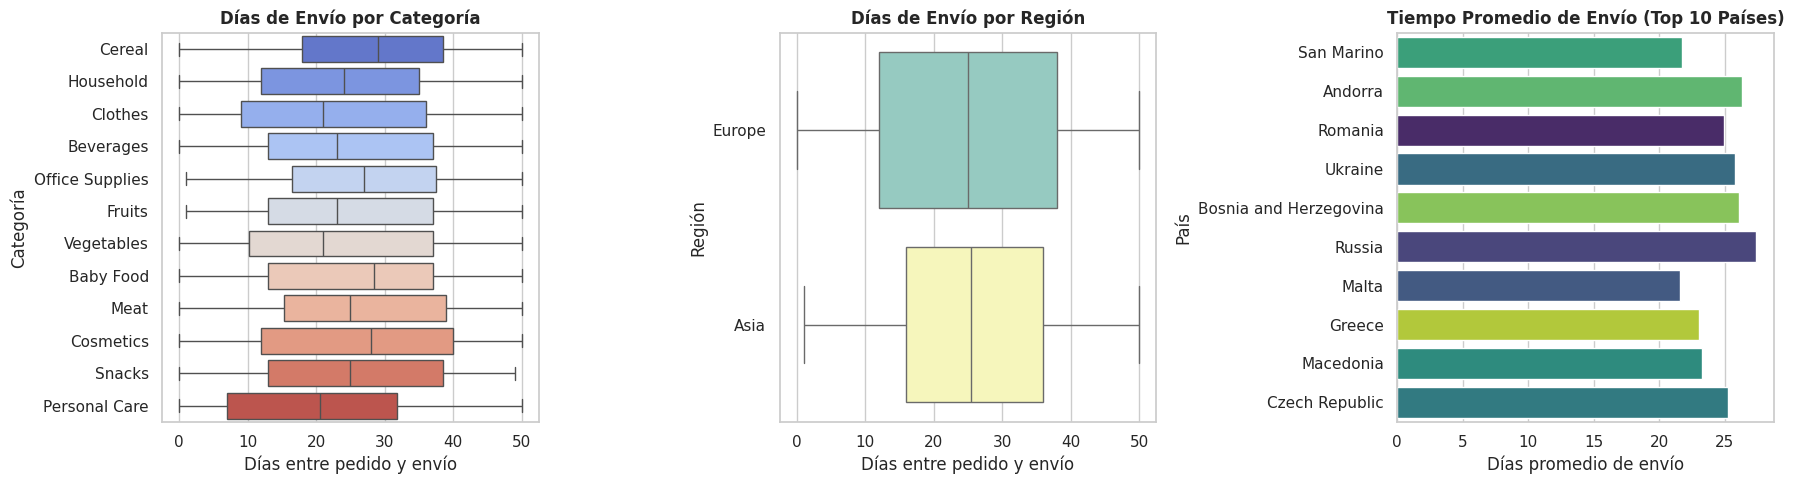

,count,mean,median,std,min,max
shipping_days,"1,328.00",24.79,25.00,14.59,0.00,50.00


,media,mediana,desv_est,min,max
category,,,,,
Baby Food,26.34,28.50,14.28,0,50
Beverages,24.12,23.00,14.48,0,50
Cereal,27.18,29.00,13.72,0,50
Clothes,23.10,21.00,15.44,0,50
Cosmetics,25.91,28.00,15.46,0,50
Fruits,24.42,23.00,13.84,1,50
Household,23.94,24.00,13.71,0,50
Meat,25.91,25.00,14.78,0,50
Office Supplies,26.71,27.00,13.42,1,50


In [50]:
top10_names = list(df_geo["country"].value_counts().head(10).index)
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=df, x="shipping_days", y="category", hue="category", palette="coolwarm", legend=False, ax=axes[0])
axes[0].set_title("Días de Envío por Categoría", fontweight="bold"); axes[0].set_xlabel("Días entre pedido y envío"); axes[0].set_ylabel("Categoría")
sns.boxplot(data=df_geo, x="shipping_days", y="region", hue="region", palette="Set3", legend=False, ax=axes[1])
axes[1].set_title("Días de Envío por Región", fontweight="bold"); axes[1].set_xlabel("Días entre pedido y envío"); axes[1].set_ylabel("Región")
sns.barplot(data=df_geo[df_geo["country"].isin(top10_names)], x="shipping_days", y="country", order=top10_names, errorbar=None,
            hue="country", palette="viridis", legend=False, ax=axes[2])
axes[2].set_title("Tiempo Promedio de Envío (Top 10 Países)", fontweight="bold"); axes[2].set_xlabel("Días promedio de envío"); axes[2].set_ylabel("País")
guardar("07_envio_categoria_region_pais.png")
display(df["shipping_days"].agg(["count", "mean", "median", "std", "min", "max"]).to_frame().T)
display(df.groupby("category")["shipping_days"].agg(media="mean", mediana="median", desv_est="std", min="min", max="max"))

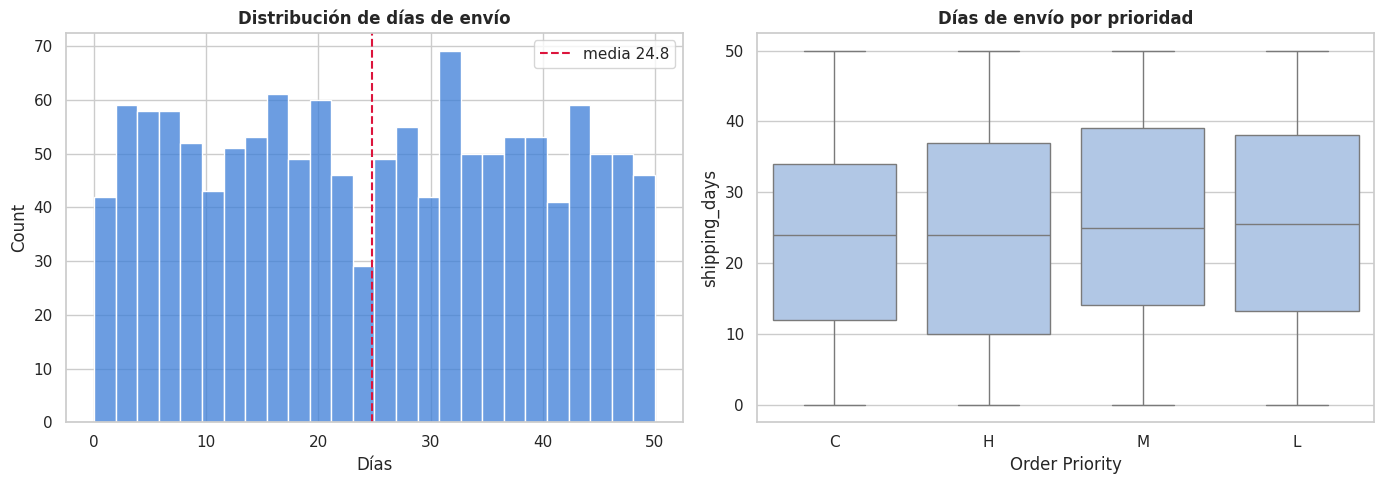

Kruskal días de envío por prioridad: p = 0.258


In [51]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.histplot(df["shipping_days"], bins=26, ax=ax[0], color="#3b7dd8")
ax[0].axvline(df["shipping_days"].mean(), color="crimson", ls="--", label=f"media {df['shipping_days'].mean():.1f}")
ax[0].set_title("Distribución de días de envío", fontweight="bold"); ax[0].set_xlabel("Días"); ax[0].legend()
sns.boxplot(data=df, x="Order Priority", y="shipping_days", order=["C", "H", "M", "L"], ax=ax[1], color="#a8c5ee")
ax[1].set_title("Días de envío por prioridad", fontweight="bold")
guardar("08_distribucion_envio_prioridad.png")
h_prio, p_prio = stats.kruskal(*[g["shipping_days"].values for _, g in df.groupby("Order Priority")])
print(f"Kruskal días de envío por prioridad: p = {p_prio:.3f}")

Pearson: r = 0.0603, p = 0.0280, r² = 0.36% | Spearman: rho = 0.0581, p = 0.0342


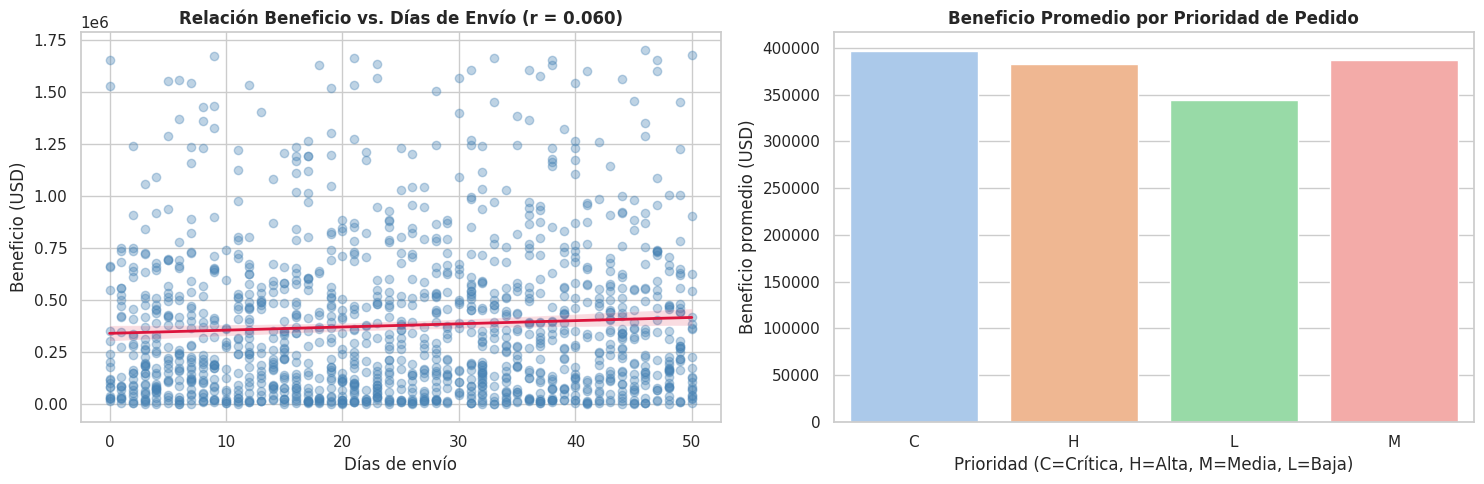

,Order Priority,dias_envio,beneficio_prom,pedidos
0,C,23.72,"396,938.10",306
1,H,24.32,"383,001.17",335
2,L,25.10,"343,937.39",334
3,M,25.86,"387,509.69",353


,r_pearson,dias_envio_prom,beneficio_prom
category,,,
Baby Food,-0.01,26.34,"481,616.05"
Beverages,0.09,24.12,"79,352.58"
Cereal,0.05,27.18,"400,534.31"
Clothes,-0.07,23.10,"413,631.57"
Cosmetics,0.12,25.91,"813,362.33"
Fruits,-0.09,24.42,"12,731.51"
Household,-0.03,23.94,"752,190.38"
Meat,0.03,25.91,"275,797.60"
Office Supplies,0.16,26.71,"633,960.78"


In [52]:
r, p_r = stats.pearsonr(df["shipping_days"], df["profit"])
rho, p_rho = stats.spearmanr(df["shipping_days"], df["profit"])
print(f"Pearson: r = {r:.4f}, p = {p_r:.4f}, r² = {r**2:.2%} | Spearman: rho = {rho:.4f}, p = {p_rho:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.regplot(data=df, x="shipping_days", y="profit", scatter_kws={"alpha": 0.35, "color": "steelblue"}, line_kws={"color": "crimson", "linewidth": 2}, ax=axes[0])
axes[0].set_title(f"Relación Beneficio vs. Días de Envío (r = {r:.3f})", fontweight="bold")
axes[0].set_xlabel("Días de envío"); axes[0].set_ylabel("Beneficio (USD)")
prio = df.groupby("Order Priority", as_index=False).agg(dias_envio=("shipping_days", "mean"), beneficio_prom=("profit", "mean"), pedidos=("Order ID", "nunique"))
sns.barplot(data=prio, x="Order Priority", y="beneficio_prom", hue="Order Priority", palette="pastel", legend=False, ax=axes[1])
axes[1].set_title("Beneficio Promedio por Prioridad de Pedido", fontweight="bold")
axes[1].set_xlabel("Prioridad (C=Crítica, H=Alta, M=Media, L=Baja)"); axes[1].set_ylabel("Beneficio promedio (USD)")
guardar("09_envio_vs_beneficio_prioridad.png")
display(prio)
display(df.groupby("category")[["shipping_days", "profit"]].apply(lambda g: pd.Series({"r_pearson": g["shipping_days"].corr(g["profit"]),
        "dias_envio_prom": g["shipping_days"].mean(), "beneficio_prom": g["profit"].mean()})))

El tiempo de envío no explica el beneficio. La prioridad del pedido tampoco acorta el envío de forma detectable.

## 7. Tiempo

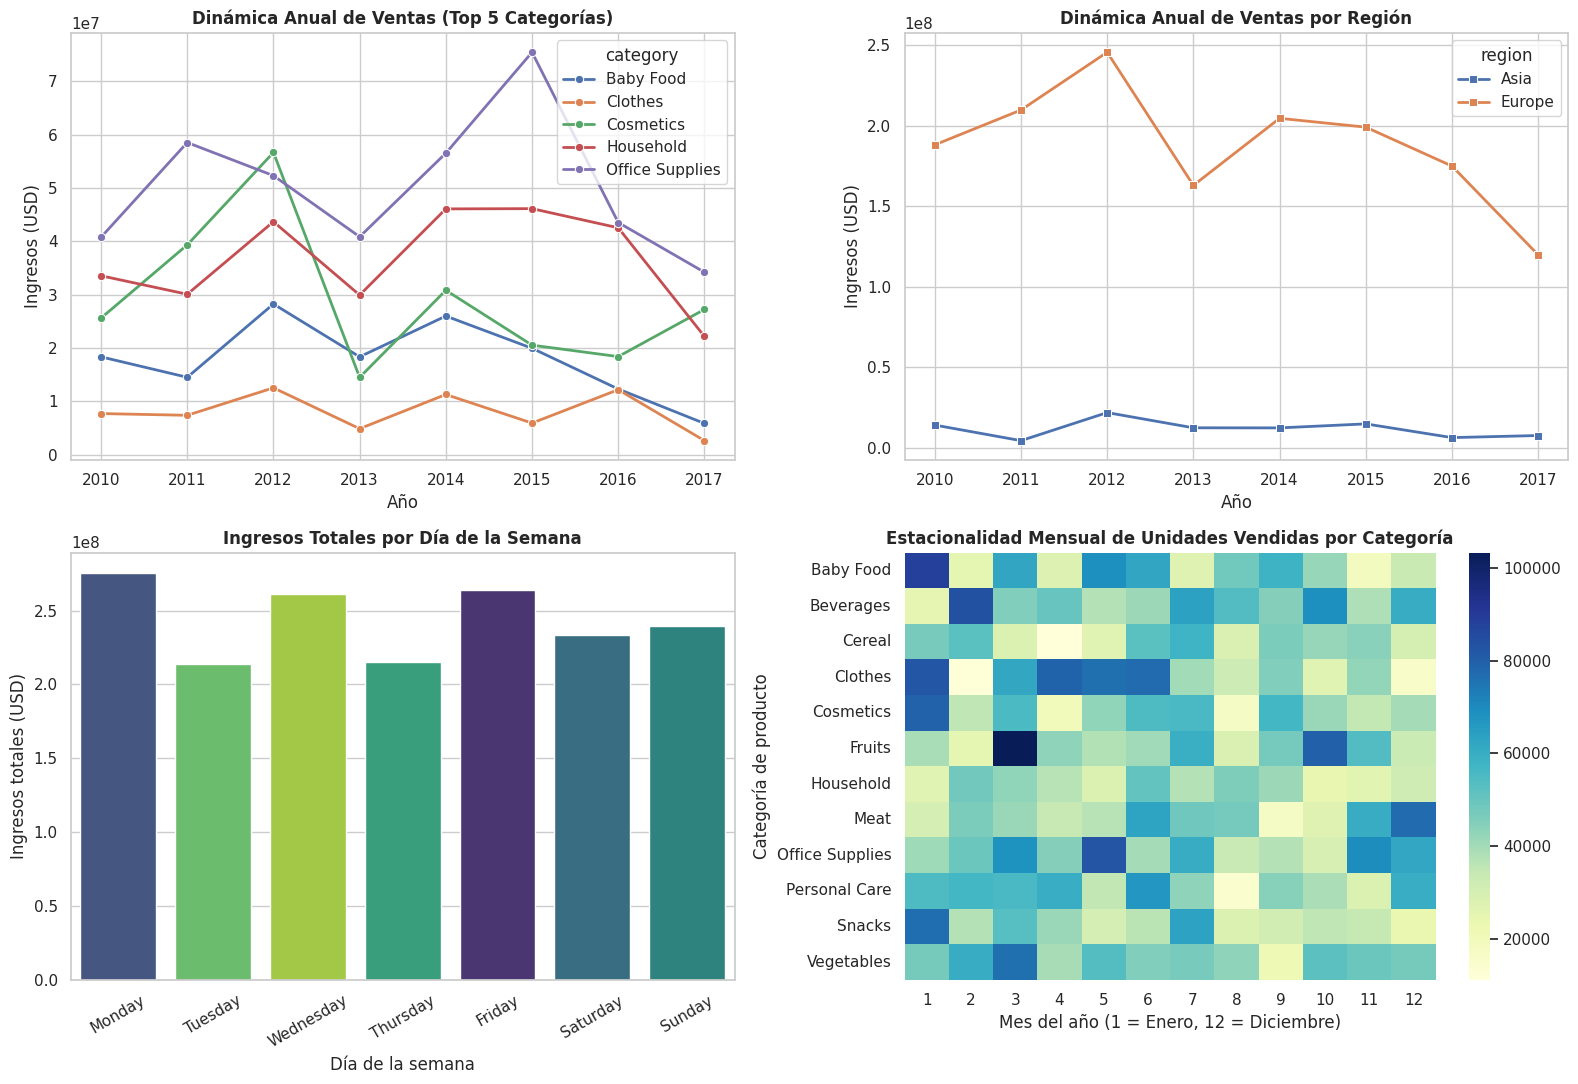

,revenue
weekday,
Monday,"275,468,475.80"
Tuesday,"213,523,894.55"
Wednesday,"261,215,696.73"
Thursday,"214,922,230.51"
Friday,"263,807,003.93"
Saturday,"233,641,145.43"
Sunday,"239,550,961.26"


month,1,2,3,4,5,6,7,8,9,10,11,12
category,,,,,,,,,,,,
Baby Food,88241,25381,62421,27516,68916,62530,27179,48518,57934,41933,18969,33168
Beverages,25044,83675,45403,50222,37113,41291,63724,54252,44783,68894,38307,60425
Cereal,47096,52382,28302,11069,26506,52494,57628,28471,46018,41911,43936,29872
Clothes,82227,11854,61721,78946,76110,77200,39904,32363,45571,26846,42669,15974
Cosmetics,79399,35359,55257,19837,42803,54836,55505,17545,56709,41504,34659,39878
Fruits,39041,25183,103302,43371,37558,40479,59665,28708,47750,79597,54065,32953
Household,26435,48054,42901,36853,28355,50987,37086,45941,41016,24395,26147,32079
Meat,30175,46317,41403,33977,36973,63135,48656,47782,17521,27025,60150,77266
Office Supplies,40839,49285,68193,44805,82505,39796,60214,33637,37286,29405,69743,61933


Pedidos por celda categoría-mes del mapa de calor: media 9.2, mínimo 3, máximo 16


In [53]:
orden_dias = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
top5_cats = cat.index[:5].tolist()
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
d1 = df[df["category"].isin(top5_cats)].groupby(["year", "category"], as_index=False)["revenue"].sum()
sns.lineplot(data=d1, x="year", y="revenue", hue="category", marker="o", linewidth=2, ax=axes[0, 0])
axes[0, 0].set_title("Dinámica Anual de Ventas (Top 5 Categorías)", fontweight="bold"); axes[0, 0].set_xlabel("Año"); axes[0, 0].set_ylabel("Ingresos (USD)")
d2 = df_geo.groupby(["year", "region"], as_index=False)["revenue"].sum()
sns.lineplot(data=d2, x="year", y="revenue", hue="region", marker="s", linewidth=2, ax=axes[0, 1])
axes[0, 1].set_title("Dinámica Anual de Ventas por Región", fontweight="bold"); axes[0, 1].set_xlabel("Año"); axes[0, 1].set_ylabel("Ingresos (USD)")
vd = df.groupby("weekday", as_index=False)["revenue"].sum()
sns.barplot(data=vd, x="weekday", y="revenue", order=orden_dias, hue="weekday", palette="viridis", legend=False, ax=axes[1, 0])
axes[1, 0].set_title("Ingresos Totales por Día de la Semana", fontweight="bold"); axes[1, 0].set_xlabel("Día de la semana"); axes[1, 0].set_ylabel("Ingresos totales (USD)")
axes[1, 0].tick_params(axis="x", rotation=30)
piv = df.pivot_table(index="category", columns="month", values="Units Sold", aggfunc="sum").reindex(columns=range(1, 13))
sns.heatmap(piv, cmap="YlGnBu", annot=False, ax=axes[1, 1])
axes[1, 1].set_title("Estacionalidad Mensual de Unidades Vendidas por Categoría", fontweight="bold")
axes[1, 1].set_xlabel("Mes del año (1 = Enero, 12 = Diciembre)"); axes[1, 1].set_ylabel("Categoría de producto")
guardar("10_dinamica_semana_estacionalidad.png")
display(vd.set_index("weekday").reindex(orden_dias))
display(piv.fillna(0).astype(int))
celdas = df.groupby(["category", "month"]).size()
print(f"Pedidos por celda categoría-mes del mapa de calor: media {celdas.mean():.1f}, mínimo {celdas.min()}, máximo {celdas.max()}")

,pedidos,ingresos,beneficio
year,,,
2010,166,"209,382,247.40","61,422,459.90"
2011,175,"231,937,556.67","69,044,659.73"
2012,202,"285,485,891.76","87,884,066.44"
2013,158,"182,962,359.28","53,387,995.18"
2014,186,"236,285,823.33","71,189,625.60"
2015,160,"227,954,098.84","61,734,039.82"
2016,175,"191,520,956.77","57,771,920.85"
2017,106,"136,600,474.16","38,999,691.48"


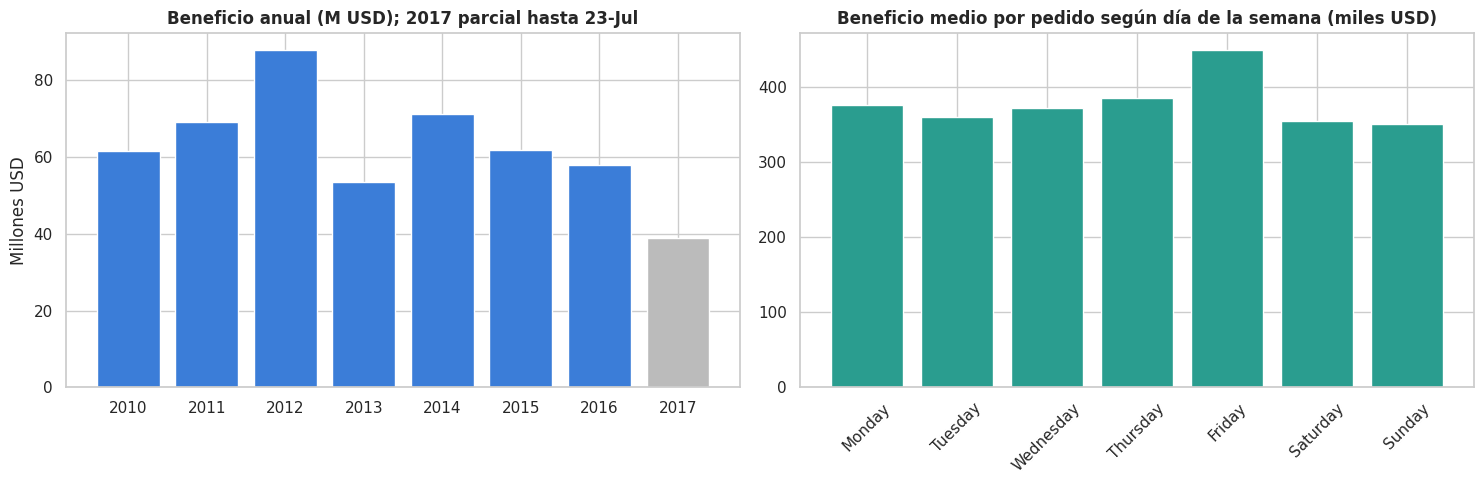

Kruskal beneficio por pedido según día de la semana: H = 4.17, p = 0.653


In [54]:
anual = df.groupby("year").agg(pedidos=("Order ID", "count"), ingresos=("revenue", "sum"), beneficio=("profit", "sum"))
ult = df["Order Date"].max()
sem = df.groupby("weekday").agg(pedidos=("Order ID", "count"), beneficio_medio=("profit", "mean")).reindex(orden_dias)
h_sem, p_sem = stats.kruskal(*[g["profit"].values for _, g in df.groupby("weekday")])
display(anual)

fig, ax = plt.subplots(1, 2, figsize=(15, 5))
ax[0].bar(anual.index.astype(str), anual["beneficio"] / 1e6, color=["#3b7dd8"] * (len(anual) - 1) + ["#bbbbbb"])
ax[0].set_title(f"Beneficio anual (M USD); {anual.index.max()} parcial hasta {ult:%d-%b}", fontweight="bold"); ax[0].set_ylabel("Millones USD")
ax[1].bar(sem.index, sem["beneficio_medio"] / 1e3, color="#2a9d8f")
ax[1].set_title("Beneficio medio por pedido según día de la semana (miles USD)", fontweight="bold"); ax[1].tick_params(axis="x", rotation=45)
guardar("11_beneficio_anual_semana.png")
print(f"Kruskal beneficio por pedido según día de la semana: H = {h_sem:.2f}, p = {p_sem:.3f}")

Con pocos pedidos por celda en el mapa de calor y sin diferencia estadística por día de la semana, los «picos» visibles no son evidencia de estacionalidad. 2017 está incompleto.

## 8. Hallazgos y recomendación

In [55]:
def lectura_p(p):
    return "diferencia estadísticamente detectable" if p < ALPHA else "sin evidencia de diferencia"

of, bev, fru = cat.loc["Office Supplies"], cat.loc["Beverages"], cat.loc["Fruits"]
eu, asia = reg.loc["Europe"], reg.loc["Asia"]
informe = f'''
### Resumen ejecutivo
Sobre **{K["pedidos"]:,} pedidos**, los ingresos suman **{usd(K["ingresos"])}** y el beneficio **{usd(K["beneficio"])}** (margen {K["margen"]:.1%}; ticket promedio {usd(K["ticket"])}).

**Recomendación:** concentrar el esfuerzo por **categoría**, no por país. Priorizar {", ".join(cat.index[:4])} ({top4:.1%} del beneficio) y revisar el precio o la permanencia de {", ".join(cat.index[-3:])} ({bottom3:.1%}).

### Hallazgo 1 · La categoría decide el beneficio
- {cat.index[0]} lidera con {usd(cat.iloc[0]["beneficio"])} ({cat.iloc[0]["%_beneficio"]:.1%}) y margen {cat.iloc[0]["margen"]:.1%}.
- Office Supplies factura más ({usd(of["ingresos"])}) pero su margen es {of["margen"]:.1%}.
- {cat.index[-1]} aporta {cat.iloc[-1]["%_beneficio"]:.1%} del beneficio: precio unitario ${fru["precio_unit"]:.2f}, ${fru["margen_unit"]:.2f} de margen por unidad.
- Beverages tiene margen {bev["margen"]:.1%} (más que Office Supplies), pero su beneficio es bajo por el **precio unitario** (${bev["precio_unit"]:.2f}), no por el margen.

### Hallazgo 2 · Los países no se diferencian
- Los 10 primeros países suman {top10_share:.1%} del beneficio (un reparto parejo daría 22.2 %).
- Beneficio por pedido entre países: p = {p_pais:.3f} → {lectura_p(p_pais)}. Mezcla de categorías por país: p = {chi_p:.3f}.
- Europa aporta {eu["beneficio"]/(eu["beneficio"]+asia["beneficio"]):.1%} del beneficio con país y {eu["pedidos"]/(eu["pedidos"]+asia["pedidos"]):.1%} de los pedidos.

### Hallazgo 3 · Canal, envío y calendario no explican el beneficio
- Online vs Offline: p = {p_canal:.3f} → {lectura_p(p_canal)}.
- Envío vs beneficio: r = {r:.3f}, p = {p_r:.3f}. {"Relación estadísticamente detectable pero despreciable" if p_r < ALPHA else "Sin relación detectable"} (r² = {r**2:.2%}).
- Día de la semana: p = {p_sem:.3f} → {lectura_p(p_sem)}.
- Beneficio anual entre {usd(anual["beneficio"].iloc[:-1].min())} y {usd(anual["beneficio"].iloc[:-1].max())}, sin tendencia clara; {anual.index.max()} llega solo hasta {ult:%d-%b}.
'''
display(Markdown(informe.replace("$", r"\$")))


### Resumen ejecutivo
Sobre **1,328 pedidos**, los ingresos suman **\$1,702,129,408** y el beneficio **\$501,434,459** (margen 29.5%; ticket promedio \$1,281,724).

**Recomendación:** concentrar el esfuerzo por **categoría**, no por país. Priorizar Cosmetics, Office Supplies, Household, Baby Food (59.4% del beneficio) y revisar el precio o la permanencia de Personal Care, Beverages, Fruits (5.0%).

### Hallazgo 1 · La categoría decide el beneficio
- Cosmetics lidera con \$92,723,306 (18.5%) y margen 39.8%.
- Office Supplies factura más (\$402,213,996) pero su margen es 19.4%.
- Fruits aporta 0.3% del beneficio: precio unitario \$9.33, \$2.41 de margen por unidad.
- Beverages tiene margen 33.0% (más que Office Supplies), pero su beneficio es bajo por el **precio unitario** (\$47.45), no por el margen.

### Hallazgo 2 · Los países no se diferencian
- Los 10 primeros países suman 29.3% del beneficio (un reparto parejo daría 22.2 %).
- Beneficio por pedido entre países: p = 0.974 → sin evidencia de diferencia. Mezcla de categorías por país: p = 0.727.
- Europa aporta 94.7% del beneficio con país y 93.4% de los pedidos.

### Hallazgo 3 · Canal, envío y calendario no explican el beneficio
- Online vs Offline: p = 0.664 → sin evidencia de diferencia.
- Envío vs beneficio: r = 0.060, p = 0.028. Relación estadísticamente detectable pero despreciable (r² = 0.36%).
- Día de la semana: p = 0.653 → sin evidencia de diferencia.
- Beneficio anual entre \$53,387,995 y \$87,884,066, sin tendencia clara; 2017 llega solo hasta 23-Jul.


## 9. Limitaciones

- **Datos simulados.** Hay 12 productos con precio y costo fijos. El beneficio por categoría refleja sobre todo el precio asignado, no el comportamiento de clientes. Los repartos casi uniformes (canal, prioridad, días de envío) son típicos de datos generados.
- **Alcance.** Solo Europa y Asia (45 países). No es un análisis global.
- **Sin país.** El 6 % de los pedidos no tiene país. Entran en los totales y salen de los cortes geográficos.
- **Sin canastas.** Cada pedido tiene una sola línea de producto: no se puede analizar venta cruzada.
- **Estacionalidad.** Con unos 10 pedidos por celda categoría-mes, el mapa de calor no permite afirmar patrones.
- **2017 parcial.** Los datos terminan en julio de 2017.
- **Pedidos excluidos.** Se eliminaron los 2 pedidos con `Units Sold` nulo en lugar de imputarlos.